# 🏦 Kredi Skorlama: Başvuru Geri Ödenecek mi?

Bir banka kredi başvurusunu değerlendirirken tek bir soruya cevap arar: **Bu kişi krediyi geri öder mi?**
Bu defterde 1.000 gerçek kredi başvurusundan öğrenen bir model kuruyor ve bankacılıkta kullanılan biçimde değerlendiriyoruz:

1. **Keşifsel analiz:** Hangi özellikler temerrütle ilişkili?
2. **Model karşılaştırma:** Lojistik regresyon, Random Forest, Gradient Boosting (ROC-AUC, Gini, KS)
3. **Maliyete duyarlı karar:** Kötü bir krediyi onaylamak, iyi bir müşteriyi reddetmekten **5 kat** pahalıdır. Onay eşiği buna göre seçilir.
4. **Puan kartı (scorecard):** Modeli, bankaların kullandığı 300–850 aralığına benzer bir *kredi puanına* çeviririz.

**Veri:** [UCI Statlog German Credit](https://doi.org/10.24432/C5NC77): 1.000 başvuru, 20 özellik, %30 temerrüt.

> **Etik not:** Veride *cinsiyet/medeni durum* ve *yabancı çalışan* bilgisi var. Bunlar ayrımcılık riski taşıdığı ve birçok ülkede kredi kararında kullanılması yasak olduğu için **modele alınmadı**.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

RENK = {"mavi": "#1F5AA6", "kirmizi": "#C8102E", "sari": "#E3A21A", "yesil": "#1B7F4B",
        "mor": "#6A1B9A", "gri": "#8A8F98", "turkuaz": "#138D90"}
PALET = [RENK[k] for k in ["mavi", "kirmizi", "sari", "yesil", "mor", "turkuaz", "gri"]]
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 13, "font.size": 10.5, "axes.prop_cycle": plt.cycler(color=PALET),
})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def kaydet(fig, ad):
    fig.tight_layout()
    fig.savefig(f"grafikler/{ad}.png", bbox_inches="tight", facecolor="white")

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.veri import yukle

df = yukle()
print(f"{len(df)} başvuru, temerrüt oranı: %{100 * df.temerrut.mean():.0f}")
df.head(3).T

1000 başvuru, temerrüt oranı: %30


,0,1,2
hesap_durumu,eksi bakiye,0–200 DM,vadesiz hesap yok
vade_ay,6,48,12
kredi_gecmisi,kritik hesap / başka bankada kredi,mevcutlar düzenli ödeniyor,kritik hesap / başka bankada kredi
amac,radyo / TV,radyo / TV,eğitim
tutar,1169,5951,2096
birikim,bilinmiyor / yok,<100 DM,<100 DM
calisma_suresi,7+ yıl,1–4 yıl,4–7 yıl
taksit_gelir_orani,4,2,2
medeni_durum_cinsiyet,erkek: bekâr,kadın: boşanmış/ayrı/evli,erkek: bekâr
kefil,yok,yok,yok


## 1. Keşifsel analiz

Önce tek tek özelliklerin temerrüt oranıyla ilişkisine bakalım. Kesikli çizgi genel ortalama (%30).

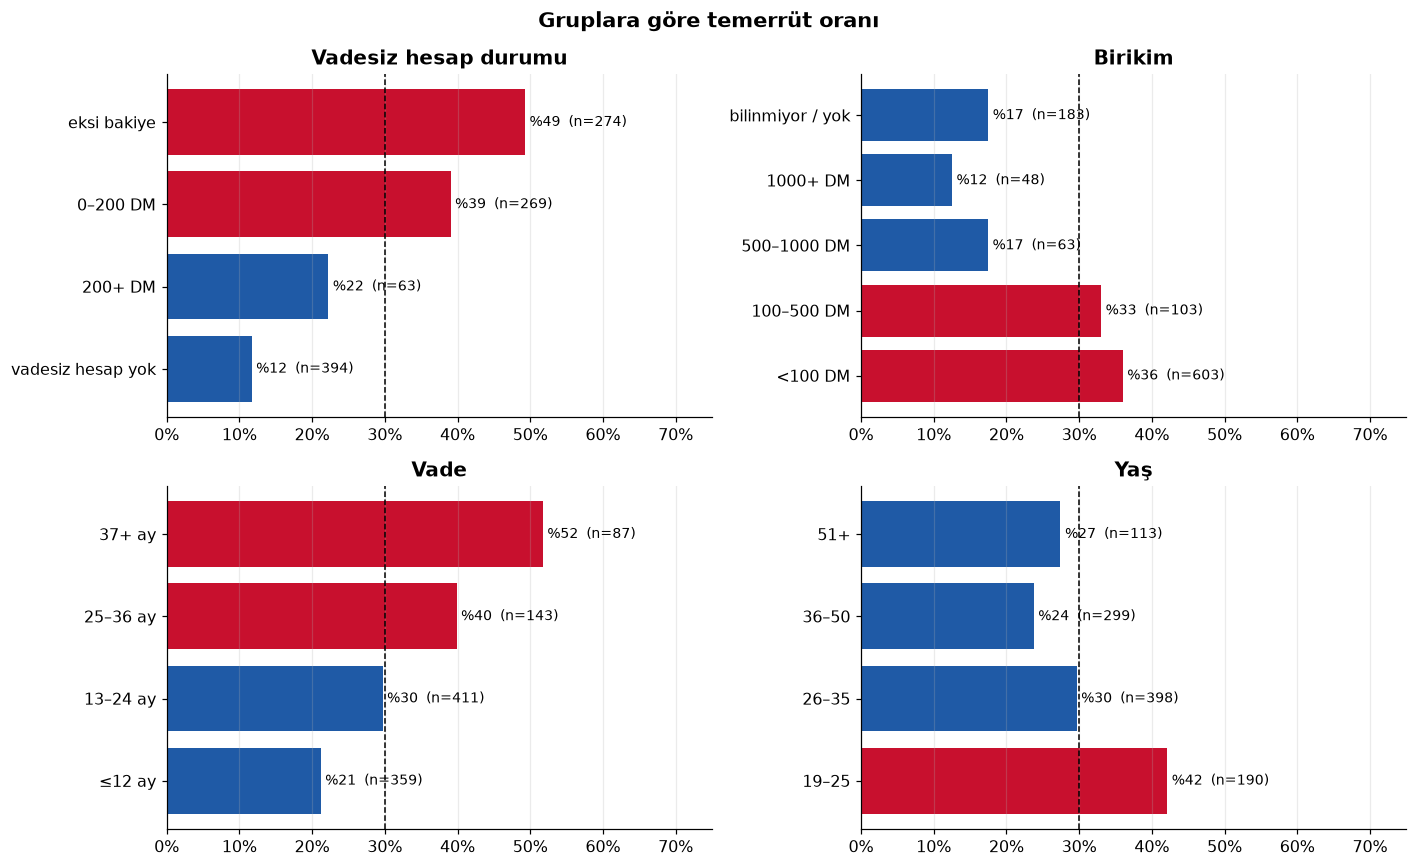

In [2]:
def oran_grafigi(ax, sutun, baslik, sira=None):
    g = df.groupby(sutun).temerrut.agg(["mean", "size"])
    g = g.loc[sira] if sira else g.sort_values("mean")
    cubuk = ax.barh(g.index, g["mean"] * 100, color=[RENK["kirmizi"] if v > df.temerrut.mean() else RENK["mavi"] for v in g["mean"]])
    ax.bar_label(cubuk, labels=[f"%{100*m:.0f}  (n={n})" for m, n in zip(g["mean"], g["size"])], padding=3, fontsize=9)
    ax.axvline(100 * df.temerrut.mean(), color="black", ls="--", lw=1)
    ax.set_title(baslik); ax.set_xlim(0, 75); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.grid(axis="y", visible=False)

fig, eks = plt.subplots(2, 2, figsize=(13, 8))
oran_grafigi(eks[0, 0], "hesap_durumu", "Vadesiz hesap durumu")
oran_grafigi(eks[0, 1], "birikim", "Birikim", ["<100 DM", "100–500 DM", "500–1000 DM", "1000+ DM", "bilinmiyor / yok"])
df["vade_grubu"] = pd.cut(df.vade_ay, [0, 12, 24, 36, 72], labels=["≤12 ay", "13–24 ay", "25–36 ay", "37+ ay"])
oran_grafigi(eks[1, 0], "vade_grubu", "Vade", ["≤12 ay", "13–24 ay", "25–36 ay", "37+ ay"])
df["yas_grubu"] = pd.cut(df.yas, [18, 25, 35, 50, 80], labels=["19–25", "26–35", "36–50", "51+"])
oran_grafigi(eks[1, 1], "yas_grubu", "Yaş", ["19–25", "26–35", "36–50", "51+"])
fig.suptitle("Gruplara göre temerrüt oranı", fontweight="bold", fontsize=14)
kaydet(fig, "1_kesifsel")
plt.show()
df = df.drop(columns=["vade_grubu", "yas_grubu"])

**Gözlemler:**
- Vadesiz hesabı **eksi bakiyede** olanların temerrüt oranı, hesabı olmayanların yaklaşık 4 katı.
- **Vade uzadıkça risk artıyor.** Uzun vade, belirsizliğin daha uzun sürmesi demek.
- **Genç başvuranlar** daha riskli görünüyor.

## 2. Modelleme

Veriyi %75 eğitim ve %25 test olarak ayırıyoruz. Test kümesine yalnızca en sonda bakılır.
Kategorik değişkenler *one-hot* kodlanır, sayısal değişkenler standartlaştırılır.

In [3]:
HARIC = ["medeni_durum_cinsiyet", "yabanci_calisan"]   # etik nedenle modele alınmıyor
X = df.drop(columns=["temerrut"] + HARIC)
y = df.temerrut
kategorik = X.select_dtypes("object").columns.tolist()
sayisal = X.select_dtypes("number").columns.tolist()

X_egitim, X_test, y_egitim, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

def on_isleme():
    return ColumnTransformer([
        ("kat", OneHotEncoder(handle_unknown="ignore"), kategorik),
        ("say", StandardScaler(), sayisal),
    ])

modeller = {
    "Lojistik regresyon": make_pipeline(on_isleme(), LogisticRegression(C=0.3, max_iter=2000)),
    "Random Forest": make_pipeline(on_isleme(), RandomForestClassifier(n_estimators=500, min_samples_leaf=5, random_state=42, n_jobs=-1)),
    "Gradient Boosting": make_pipeline(on_isleme(), HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=300, l2_regularization=1.0, random_state=42)),
}

def ks(y_gercek, p):
    fpr, tpr, _ = roc_curve(y_gercek, p)
    return (tpr - fpr).max()

cv = StratifiedKFold(5, shuffle=True, random_state=42)
satirlar = []
for ad, model in modeller.items():
    cv_auc = cross_val_score(model, X_egitim, y_egitim, cv=cv, scoring="roc_auc")
    model.fit(X_egitim, y_egitim)
    p = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, p)
    satirlar.append({"Model": ad, "CV AUC": cv_auc.mean(), "CV ± std": cv_auc.std(),
                     "Test AUC": auc, "Test Gini": 2 * auc - 1, "Test KS": ks(y_test, p)})
sonuc = pd.DataFrame(satirlar).set_index("Model")
sonuc

,CV AUC,CV ± std,Test AUC,Test Gini,Test KS
Model,,,,,
Lojistik regresyon,0.766,0.021,0.804,0.608,0.528
Random Forest,0.786,0.015,0.797,0.594,0.501
Gradient Boosting,0.774,0.030,0.794,0.587,0.470


**Metrikler:**
- **ROC-AUC:** Rastgele seçilen bir kötü kredinin, rastgele bir iyi krediden daha yüksek risk puanı alma olasılığı. 0,5 yazı-tura, 1 kusursuz.
- **Gini = 2·AUC − 1:** Bankacılıkta raporlanan standart ölçü.
- **KS:** İyi ve kötü kredilerin puan dağılımları arasındaki en büyük fark.

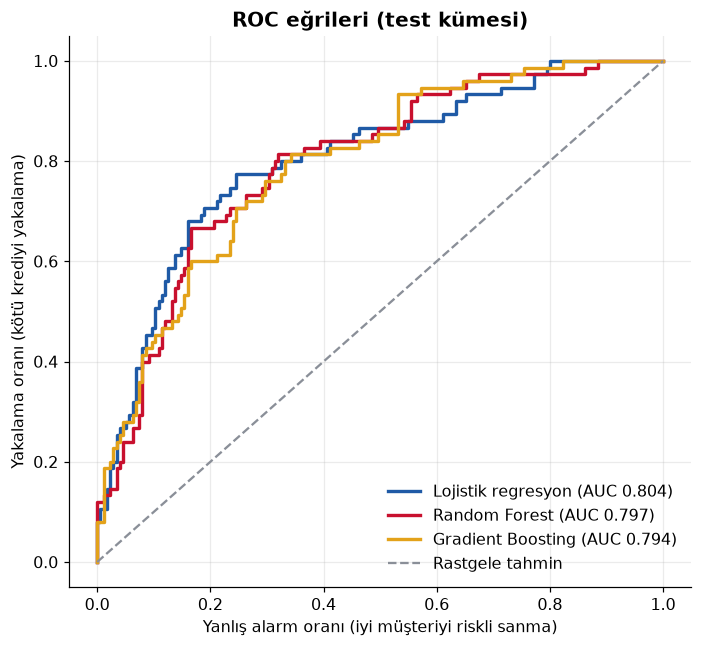

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for (ad, model), renk in zip(modeller.items(), PALET):
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, lw=2.2, color=renk, label=f"{ad} (AUC {sonuc.loc[ad, 'Test AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=RENK["gri"], label="Rastgele tahmin")
ax.set_xlabel("Yanlış alarm oranı (iyi müşteriyi riskli sanma)")
ax.set_ylabel("Yakalama oranı (kötü krediyi yakalama)")
ax.set_title("ROC eğrileri (test kümesi)")
ax.legend(frameon=False, loc="lower right")
kaydet(fig, "2_roc")
plt.show()

Üç modelin farkı küçük. 1.000 satırlık veride **lojistik regresyon** karmaşık modellerle başa baş gidiyor.
Üstelik yorumlanabilir: bankacılık düzenlemeleri, bir başvurunun *neden* reddedildiğini açıklayabilmeyi şart koşar.
Bu yüzden devam eden bölümlerde lojistik regresyonu kullanıyoruz.

## 3. Maliyete duyarlı karar eşiği

Modelin ürettiği sayı bir **olasılık**. Hangi olasılığın üstünde başvuruyu reddedeceğimize biz karar veririz.
Veri setinin sahibi şu maliyetleri tanımlamış:

| | Model "iyi" dedi (onay) | Model "kötü" dedi (red) |
|---|---|---|
| **Gerçekte iyi** | 0 | 1 (kaçan müşteri) |
| **Gerçekte kötü** | **5** (batan kredi) | 0 |

$$\text{Maliyet}(e) = 5 \cdot FN(e) + 1 \cdot FP(e)$$

Eşiği eğitim kümesindeki **çapraz doğrulama tahminleriyle** seçiyoruz. Böylece test kümesi karar sürecine hiç karışmamış oluyor.

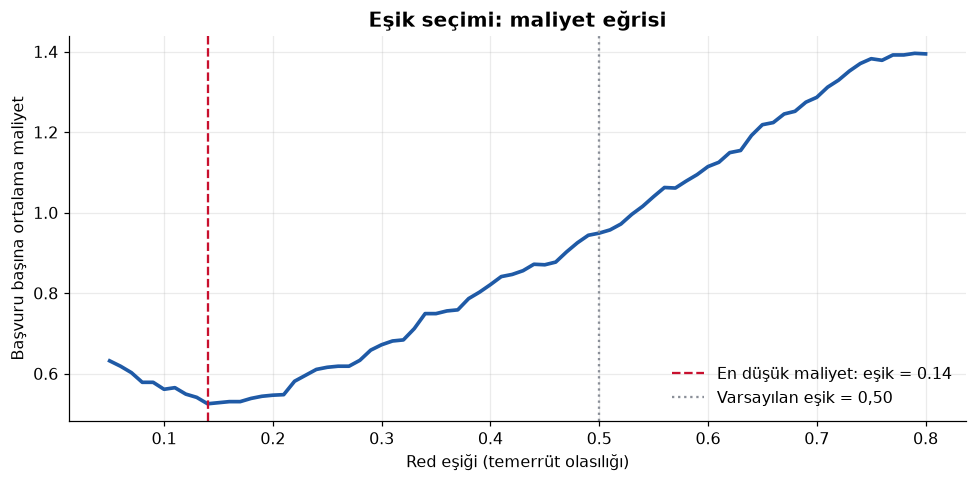

,Onay oranı,Onaylananlarda temerrüt,Yakalanan kötü kredi,Başvuru başına maliyet
Eşik,,,,
"Varsayılan (0,50)",0.768,0.188,0.520,0.796
Maliyet odaklı (0.14),0.292,0.110,0.893,0.600


In [5]:
secilen = modeller["Lojistik regresyon"]
p_oof = cross_val_predict(secilen, X_egitim, y_egitim, cv=cv, method="predict_proba")[:, 1]

def maliyet(y_gercek, p, esik):
    red = p >= esik
    return (5 * ((~red) & (y_gercek == 1)).sum() + (red & (y_gercek == 0)).sum()) / len(y_gercek)

esikler = np.linspace(0.05, 0.8, 76)
maliyetler = [maliyet(y_egitim.values, p_oof, e) for e in esikler]
en_iyi = esikler[int(np.argmin(maliyetler))]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(esikler, maliyetler, lw=2.4, color=RENK["mavi"])
ax.axvline(en_iyi, color=RENK["kirmizi"], ls="--", label=f"En düşük maliyet: eşik = {en_iyi:.2f}")
ax.axvline(0.5, color=RENK["gri"], ls=":", label="Varsayılan eşik = 0,50")
ax.set_xlabel("Red eşiği (temerrüt olasılığı)"); ax.set_ylabel("Başvuru başına ortalama maliyet")
ax.set_title("Eşik seçimi: maliyet eğrisi")
ax.legend(frameon=False)
kaydet(fig, "3_esik")
plt.show()

p_test = secilen.predict_proba(X_test)[:, 1]
karsilastir = []
for ad, e in [("Varsayılan (0,50)", 0.5), (f"Maliyet odaklı ({en_iyi:.2f})", en_iyi)]:
    tn, fp, fn, tp = confusion_matrix(y_test, p_test >= e).ravel()
    karsilastir.append({"Eşik": ad, "Onay oranı": (tn + fn) / len(y_test),
                        "Onaylananlarda temerrüt": fn / (tn + fn), "Yakalanan kötü kredi": tp / (tp + fn),
                        "Başvuru başına maliyet": maliyet(y_test.values, p_test, e)})
pd.DataFrame(karsilastir).set_index("Eşik")

## 4. Puan kartı (scorecard)

Bankalar müşteriye "temerrüt olasılığınız %12" demez, bir **kredi puanı** verir. Puan kartında her özelliğin her değeri belli bir puan getirir. Başvurunun puanı bu puanların toplamıdır.

Standart ölçekleme: **600 puan = 50'ye 1 iyi/kötü oranı** ve **her 20 puan oranı ikiye katlar** (PDO = 20).

$$\text{Puan} = \text{offset} + \text{faktör} \cdot \ln(\text{oran}_{iyi}), \qquad \text{faktör} = \frac{20}{\ln 2}, \qquad \text{offset} = 600 - \text{faktör} \cdot \ln 50$$

Puan kartının okunabilir olması için sayısal değişkenleri gruplara ayırıp her grubu ayrı bir kategori gibi ele alıyoruz.

In [6]:
def gruplandir(d):
    d = d.copy()
    d["vade_ay"] = pd.cut(d.vade_ay, [0, 12, 24, 36, 72]).astype(str)
    d["tutar"] = pd.cut(d.tutar, [0, 1500, 3000, 6000, 20000]).astype(str)
    d["yas"] = pd.cut(d.yas, [18, 25, 35, 50, 80]).astype(str)
    return d.astype(str)

kart_model = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(C=0.3, max_iter=2000))
kart_model.fit(gruplandir(X_egitim), y_egitim)
print(f"Puan kartı modelinin test AUC'si: {roc_auc_score(y_test, kart_model.predict_proba(gruplandir(X_test))[:, 1]):.3f}")

faktor = 20 / np.log(2)
offset = 600 - faktor * np.log(50)
kodlayici, lr = kart_model.named_steps["onehotencoder"], kart_model.named_steps["logisticregression"]
taban = offset - faktor * lr.intercept_[0]

kayitlar, i = [], 0
for degisken, kategoriler in zip(X_egitim.columns, kodlayici.categories_):
    for k in kategoriler:
        kayitlar.append({"değişken": degisken, "değer": k, "puan": -faktor * lr.coef_[0, i]})
        i += 1
kart = pd.DataFrame(kayitlar)
# Her değişkende en düşük puanı 0'a çekip farkı tabana aktar: okunması kolay pozitif puanlar
en_dusuk = kart.groupby("değişken").puan.transform("min")
taban += en_dusuk.groupby(kart["değişken"]).first().sum()
kart["puan"] = (kart.puan - en_dusuk).round().astype(int)
print(f"Taban puan: {taban:.0f}")
kart[kart["değişken"].isin(["hesap_durumu", "vade_ay", "birikim"])].sort_values(["değişken", "puan"])

Puan kartı modelinin test AUC'si: 0.798
Taban puan: 348


,değişken,değer,puan
30,birikim,<100 DM,0
28,birikim,100–500 DM,13
29,birikim,500–1000 DM,20
31,birikim,bilinmiyor / yok,30
27,birikim,1000+ DM,31
2,hesap_durumu,eksi bakiye,0
0,hesap_durumu,0–200 DM,7
1,hesap_durumu,200+ DM,20
3,hesap_durumu,vadesiz hesap yok,41
6,vade_ay,"(24, 36]",0


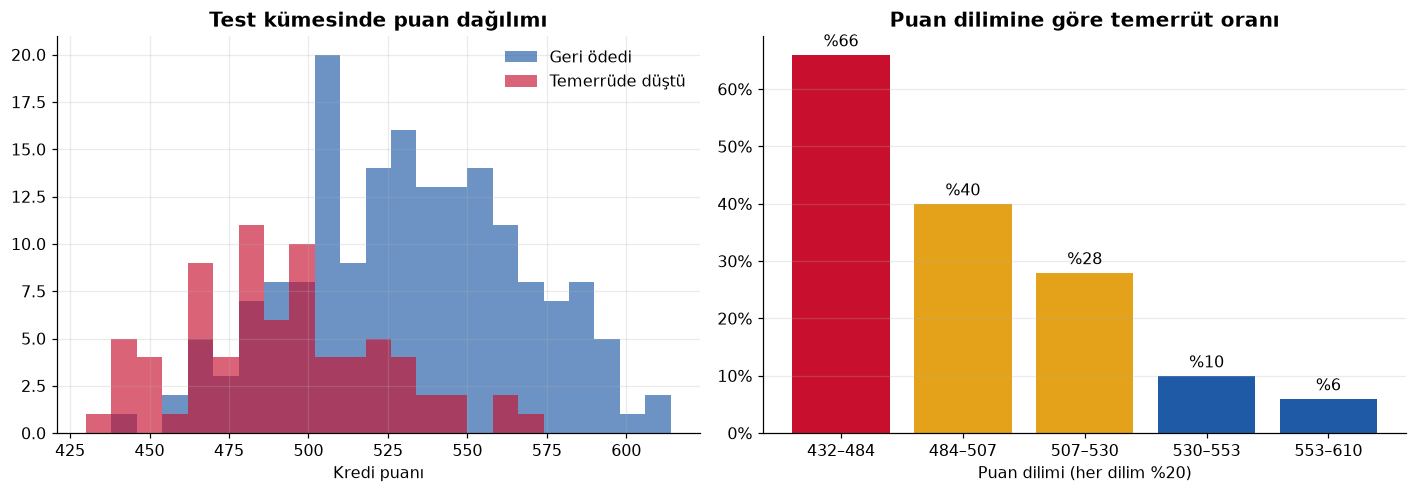

(432.95000000000005, 484.921]   66.000
(484.921, 507.049]              40.000
(507.049, 530.065]              28.000
(530.065, 553.542]              10.000
(553.542, 610.744]               6.000


In [7]:
def puanla(d):
    oh = kodlayici.transform(gruplandir(d)).toarray()
    return offset - faktor * (lr.intercept_[0] + oh @ lr.coef_[0])

puan_test = pd.Series(puanla(X_test), index=X_test.index)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
kutular = np.arange(np.floor(puan_test.min() / 10) * 10, puan_test.max() + 10, 8)
ax1.hist(puan_test[y_test == 0], bins=kutular, alpha=0.65, color=RENK["mavi"], label="Geri ödedi")
ax1.hist(puan_test[y_test == 1], bins=kutular, alpha=0.65, color=RENK["kirmizi"], label="Temerrüde düştü")
ax1.set_title("Test kümesinde puan dağılımı"); ax1.set_xlabel("Kredi puanı"); ax1.legend(frameon=False)

bantlar = pd.qcut(puan_test, 5)
bant_oran = y_test.groupby(bantlar, observed=True).mean() * 100
etiketler = [f"{int(b.left)}–{int(b.right)}" for b in bant_oran.index]
c = ax2.bar(etiketler, bant_oran.values, color=[RENK["kirmizi"], RENK["sari"], RENK["sari"], RENK["mavi"], RENK["mavi"]])
ax2.bar_label(c, labels=[f"%{v:.0f}" for v in bant_oran.values], padding=3)
ax2.set_title("Puan dilimine göre temerrüt oranı"); ax2.set_xlabel("Puan dilimi (her dilim %20)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter()); ax2.grid(axis="x", visible=False)
kaydet(fig, "4_puan_karti")
plt.show()
print(bant_oran.round(1).to_string())

## 5. Model neye bakıyor?

**Permütasyon önemi:** Bir değişkenin değerleri karıştırıldığında modelin AUC'si ne kadar düşüyor? Düşüş ne kadar büyükse model o değişkene o kadar dayanıyor demektir.

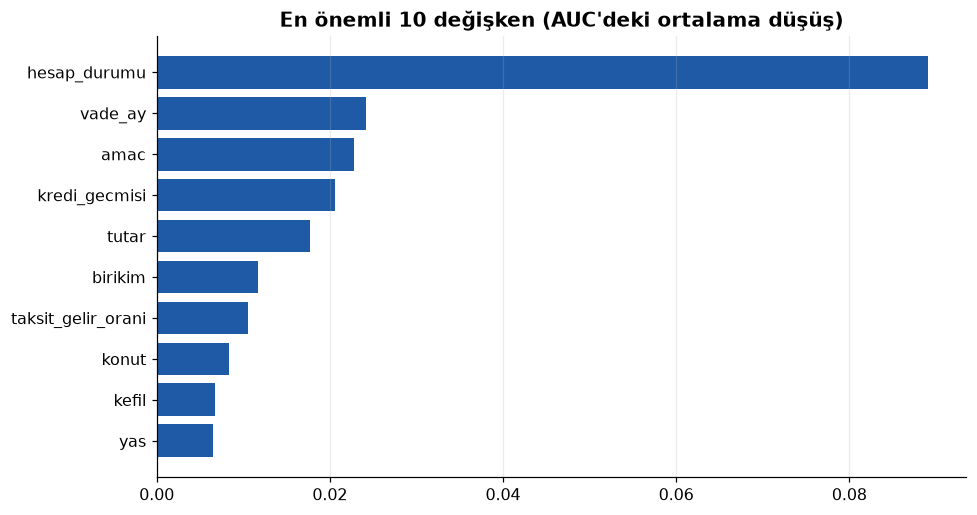

hesap_durumu         0.089
vade_ay              0.024
amac                 0.023
kredi_gecmisi        0.021
tutar                0.018
birikim              0.012
taksit_gelir_orani   0.011
konut                0.008
kefil                0.007
yas                  0.006
dtype: float64

In [8]:
onem = permutation_importance(secilen, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=42)
onem = pd.Series(onem.importances_mean, index=X_test.columns).sort_values().tail(10)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(onem.index, onem.values, color=RENK["mavi"])
ax.set_title("En önemli 10 değişken (AUC'deki ortalama düşüş)")
ax.grid(axis="y", visible=False)
kaydet(fig, "5_onem")
plt.show()
onem.sort_values(ascending=False).round(4)

## 6. Sonuçlar

| | Sonuç |
|---|---|
| En iyi model (test) | Lojistik regresyon: **AUC 0,804 · Gini 0,61 · KS 0,53** |
| Puan kartı (gruplanmış, yorumlanabilir) | AUC 0,798: okunabilirlik için yalnızca 0,006 kayıp |
| En riskli %20 / en güvenli %20 | Temerrüt oranı **%66** / **%6** |
| Maliyet odaklı eşik (0,14) | Başvuru başına maliyet 0,80 → **0,60 (−%25)** |

1. **Basit model yeterli.** 1.000 başvuruluk veride lojistik regresyon, ağaç tabanlı modellerle aynı başarıyı gösterdi. Üstelik her kararın gerekçesi açıklanabiliyor.
2. **En güçlü sinyal vadesiz hesap durumu.** Bunu vade, kredi amacı ve kredi geçmişi izliyor.
3. **Eşik bir iş kararıdır.** Kötü krediyi onaylamak 5 kat pahalıysa teorik en iyi eşik $1/(1+5) \approx 0{,}17$ olur. Çapraz doğrulamayla bulduğumuz 0,14 buna çok yakın.
4. **Ama maliyet tablosu eksik bir resim çizer.** 0,14 eşiği başvuruların yalnızca %29'unu onaylıyor. Gerçek bir banka, iyi kredilerden kazandığı faizi de hesaba katar. Maliyet yerine *kâr* tanımlanırsa eşik yukarı kayar.

### Sınırlılıklar
- Veri 1990'ların Almanya'sına ait ve küçük (1.000 satır). Yöntem genellenebilir, katsayılar genellenemez.
- Yalnızca onaylanmış başvuruların sonucu biliniyor. Reddedilenlerin geri ödeyip ödemeyeceği bilinmiyor (*reject inference* problemi).
- Hassas değişkenler çıkarıldı. Yine de dolaylı ayrımcılık (ör. yaş üzerinden) ayrıca denetlenmelidir.
